# NHL: предсказать успешность команды в следующем сезоне

**Тестовое задание • 100 баллов**

Вы аналитик, которому после окончания сезона нужно оценить перспективы команды
на следующий год. Соберите таблицу с учебного сайта
[Scrape This Site - Hockey Teams](https://www.scrapethissite.com/pages/forms/),
изучите данные и постройте модель классификации.
В работе оцениваются корректность исследования и обоснованность решений.

Ориентир времени: 6-10 часов (знание хоккея не требуется).
Можно обращаться к документации и пользоваться вспомогательными инструментами.
Укажите, чем пользовались; отвечайте за правильность и понимание сданной работы.
Подтверждайте ответы результатами из своего ноутбука.

## Что сдавать

Выполненный IPynb с видимыми результатами и ответами и исходный `data/hockey_raw.csv` разместите на платформе githib.com.
Укажите имя, дату и использованные источники и инструменты в README.

## Что предсказывает модель

Одна строка признаков описывает команду в сезоне `t`.
`target=1`, если доля побед той же команды в сезоне `t+1` строго выше медианной
доли побед всех команд в сезоне `t+1`. В остальных случаях `target=0`.

Медиану считайте по полной исходной таблице будущего года до отбора пар.
В пары включайте одинаковые названия команды с разницей меток сезонов ровно в один год.
Строки без пары исключайте и учитывайте в описании данных.
Будущий `win_rate` и будущая медиана используются для построения target и анализа
готовых прогнозов. Признаки модели должны быть известны после сезона `t`.

## Схема проверки

Делите данные по году целевого сезона:

| Часть | target_year | Назначение |
|---|---|---|
| train | не позднее 2005 | Подготовка данных и обучение |
| validation | 2006-2008 | Сравнение вариантов и выбор решения |
| test | 2009-2011 | Одна итоговая оценка выбранного решения |

Основная метрика: ROC-AUC по вероятности класса 1.
На итоговом этапе также используйте F1 и accuracy при пороге 0.5.
Финальный test используйте после выбора решения на validation.

## Как оценивается работа

| Область | Баллы |
|---|---:|
| Сбор и понимание данных | 15 |
| Построение задачи и корректность проверки | 20 |
| Исследовательский анализ | 20 |
| Модели и эксперименты | 25 |
| Итоговая оценка и анализ ошибок | 15 |
| Ясность и воспроизводимость | 5 |
| **Всего** | **100** |

Ниже перечислены обязательные этапы работы. Внутри них вы самостоятельно выбираете
исследовательские вопросы, графики, признаки, обработку данных, эксперимент и способ
разбора ошибок. Оценивается качество решений, а не совпадение с эталонным маршрутом.
Сложность метода сама по себе не даёт преимущества. Корректный эксперимент может
получить полный балл и в случае отсутствия улучшения.

## Требования к сбору

Итоговая исходная таблица должна иметь столбцы `team`, `year`, `wins`, `losses`,
`ot_losses`, `win_rate`, `goals_for`, `goals_against`, `goal_diff`.
Самостоятельно исследуйте страницу и определите способ получения всей таблицы.

**Автор:** Абайдуллин Айдар Альбертович   
**Дата:** 07.10.2026 

**Использованные источники и инструменты:** Источник данных — [Scrape This Site](https://www.scrapethissite.com/pages/forms/). Документация основных инструментов: [Requests](https://requests.readthedocs.io/) — загрузка страниц; [Beautiful Soup](https://www.crummy.com/software/BeautifulSoup/bs4/doc/) — разбор HTML; [pandas](https://pandas.pydata.org/docs/) — обработка таблиц, `groupby`, `merge`, чтение и сохранение CSV; [scikit-learn](https://scikit-learn.org/stable/) — Pipeline, StandardScaler, LogisticRegression и метрики. ChatGPT использовался для проверки кода, а также помощи в оформлении разделов и выводов.

In [1]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import time
from pathlib import Path
import matplotlib as plt
from sklearn.metrics import roc_auc_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
import sys
import sklearn
import requests
import bs4

## Раздел 1. Сбор и понимание данных: 15 баллов

### 1.1. Соберите и сохраните данные

Соберите все страницы сайта в одну таблицу с указанными девятью столбцами.
Сохраните исходную выгрузку в `data/hockey_raw.csv`. Укажите URL и дату сбора,
число обработанных страниц и число строк. Покажите, как проверили,
что сбор не ограничился первой страницей и при повторном анализе можно читать CSV.

In [2]:
url = 'https://www.scrapethissite.com/pages/forms/?page_num=1'
response = requests.get(url, timeout = 30)
response.status_code

200

In [3]:
print(response.text[:1500])

<!doctype html>
<html lang="en">
  <head>
    <meta charset="utf-8">
    <title>Hockey Teams: Forms, Searching and Pagination | Scrape This Site | A public sandbox for learning web scraping</title>
    <link rel="icon" type="image/png" href="/static/images/scraper-icon.png" />

    <meta name="viewport" content="width=device-width, initial-scale=1.0">
    <meta name="description" content="Browse through a database of NHL team stats since 1990. Practice building a scraper that handles common website interface components.">

    <link href="https://maxcdn.bootstrapcdn.com/bootstrap/3.3.5/css/bootstrap.min.css" rel="stylesheet" integrity="sha256-MfvZlkHCEqatNoGiOXveE8FIwMzZg4W85qfrfIFBfYc= sha512-dTfge/zgoMYpP7QbHy4gWMEGsbsdZeCXz7irItjcC3sPUFtf0kuFbDz/ixG7ArTxmDjLXDmezHubeNikyKGVyQ==" crossorigin="anonymous">
    <link href='https://fonts.googleapis.com/css?family=Lato:400,700' rel='stylesheet' type='text/css'>
    <link rel="stylesheet" type="text/css" href="/static/css/styles.css">

   

In [4]:
position = (response.text).find('New York Rangers')
print(position)

21694


In [5]:
print(response.text[position - 200:position + 1200])

              </td>
                        
                    </tr>
                    
                    <tr class="team">
                        <td class="name">
                            New York Rangers
                        </td>
                        <td class="year">
                            1990
                        </td>
                        <td class="wins">
                            36
                        </td>
                        <td class="losses">
                            31
                        </td>
                        <td class="ot-losses">
                            
                        </td>
                        
                        
                        <td class="pct text-danger">
                            0.45
                        </td>
                        
                        <td class="gf">
                            297
                        </td>
                        <td class="ga">
 

In [6]:
parser = BeautifulSoup(response.text, "html.parser")

In [7]:
row = parser.find('tr', class_ = 'team')

In [8]:
name_cell = row.find('td', class_ = 'name')

In [9]:
team = name_cell.get_text(strip = True)
print(team)

Boston Bruins


In [10]:
years_cell = row.find('td', class_ = 'year')
year = years_cell.get_text(strip = True)
print(year)
year = int(year)
type(year)

1990


int

In [11]:
wins_cell = row.find('td', class_ = 'wins')
wins = wins_cell.get_text(strip = True)
print(wins)
wins = int(wins)
type(wins)

44


int

In [12]:
percent = row.find('td', class_ = 'pct')
win_rate = percent.get_text(strip = True)
win_rate = float(win_rate)
type(win_rate)

float

In [13]:
ot_cell = row.find('td', class_ = 'ot-losses')
ot_l_text = ot_cell.get_text(strip = True)
if ot_l_text == "":
    ot_losses = None
else:
    ot_losses = int(ot_l_text)

In [14]:
print(ot_losses)

None


In [15]:
losses_cell = row.find('td', class_ = 'losses')
losses = losses_cell.get_text(strip = True)
losses = int(losses)
losses

24

In [16]:
goals_scored_cell = row.find('td', class_ = 'gf')
goals_for = goals_scored_cell.get_text(strip = True)
goals_for = int(goals_for)
goals_for

299

In [17]:
goals_conceded_cell = row.find('td', class_ = 'ga')
goals_against = goals_conceded_cell.get_text(strip = True)
goals_against = int(goals_against)
goals_against

264

In [18]:
goal_diff_cell = row.find('td', class_ = 'diff')
goal_diff = goal_diff_cell.get_text(strip = True)
goal_diff = int(goal_diff)
goal_diff

35

In [19]:
record = {

    'team' : team,
    'year' : year,
    'wins' : wins,
    'losses' : losses,
    'ot_losses' : ot_losses,
    'win_rate' : win_rate,
    'goals_for' : goals_for,
    'goals_against' : goals_against,
    'goal_diff' : goal_diff
}
record

{'team': 'Boston Bruins',
 'year': 1990,
 'wins': 44,
 'losses': 24,
 'ot_losses': None,
 'win_rate': 0.55,
 'goals_for': 299,
 'goals_against': 264,
 'goal_diff': 35}

In [20]:
all_rows = parser.find_all('tr', class_ = 'team')
len(all_rows)

25

In [21]:
records = []
for rows in all_rows:
    team_cell = rows.find('td', class_ = 'name')
    team = team_cell.get_text(strip = True)
    
    year_cell = rows.find('td', class_ = 'year')
    year = year_cell.get_text(strip = True)
    year = int(year)
    
    wins_cell = rows.find('td', class_ = 'wins')
    wins = wins_cell.get_text(strip = True)
    wins = int(wins)
    
    losses_cell = rows.find('td', class_ = 'losses')
    losses = losses_cell.get_text(strip = True)
    losses = int(losses)
    
    ot_losses_cell = rows.find('td', class_ = 'ot-losses')
    ot_l_text = ot_losses_cell.get_text(strip = True)
    if ot_l_text == "":
        ot_losses = None
    else:
        ot_losses = int(ot_l_text)

    win_rate_cell = rows.find('td', class_ = 'pct')
    win_rate = win_rate_cell.get_text(strip = True)
    win_rate = float(win_rate)

    goals_for_cell = rows.find('td', class_ = 'gf')
    goals_for = goals_for_cell.get_text(strip = True)
    goals_for = int(goals_for)

    goals_against_cell = rows.find('td', class_ = 'ga')
    goals_against = goals_against_cell.get_text(strip = True)
    goals_against = int(goals_against)

    goal_diff_cell = rows.find('td', class_ = 'diff')
    goal_diff = goal_diff_cell.get_text(strip = True)
    goal_diff = int(goal_diff)

    record = {     
    'team' : team,
    'year' : year,
    'wins' : wins,
    'losses' : losses,
    'ot_losses' : ot_losses,
    'win_rate' : win_rate,
    'goals_for' : goals_for,
    'goals_against' : goals_against,
    'goal_diff' : goal_diff
        }
    records.append(record)

len(records)
records

[{'team': 'Boston Bruins',
  'year': 1990,
  'wins': 44,
  'losses': 24,
  'ot_losses': None,
  'win_rate': 0.55,
  'goals_for': 299,
  'goals_against': 264,
  'goal_diff': 35},
 {'team': 'Buffalo Sabres',
  'year': 1990,
  'wins': 31,
  'losses': 30,
  'ot_losses': None,
  'win_rate': 0.388,
  'goals_for': 292,
  'goals_against': 278,
  'goal_diff': 14},
 {'team': 'Calgary Flames',
  'year': 1990,
  'wins': 46,
  'losses': 26,
  'ot_losses': None,
  'win_rate': 0.575,
  'goals_for': 344,
  'goals_against': 263,
  'goal_diff': 81},
 {'team': 'Chicago Blackhawks',
  'year': 1990,
  'wins': 49,
  'losses': 23,
  'ot_losses': None,
  'win_rate': 0.613,
  'goals_for': 284,
  'goals_against': 211,
  'goal_diff': 73},
 {'team': 'Detroit Red Wings',
  'year': 1990,
  'wins': 34,
  'losses': 38,
  'ot_losses': None,
  'win_rate': 0.425,
  'goals_for': 273,
  'goals_against': 298,
  'goal_diff': -25},
 {'team': 'Edmonton Oilers',
  'year': 1990,
  'wins': 37,
  'losses': 37,
  'ot_losses': None

In [22]:
print(len(records))
print(records[0])
print(records[1])

25
{'team': 'Boston Bruins', 'year': 1990, 'wins': 44, 'losses': 24, 'ot_losses': None, 'win_rate': 0.55, 'goals_for': 299, 'goals_against': 264, 'goal_diff': 35}
{'team': 'Buffalo Sabres', 'year': 1990, 'wins': 31, 'losses': 30, 'ot_losses': None, 'win_rate': 0.388, 'goals_for': 292, 'goals_against': 278, 'goal_diff': 14}


In [23]:
df = pd.DataFrame(records)
df.head()

,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
0,Boston Bruins,1990,44,24,None,0.550,299,264,35
1,Buffalo Sabres,1990,31,30,None,0.388,292,278,14
2,Calgary Flames,1990,46,26,None,0.575,344,263,81
3,Chicago Blackhawks,1990,49,23,None,0.613,284,211,73
4,Detroit Red Wings,1990,34,38,None,0.425,273,298,-25


In [24]:
def parse_page(html):
    parser = BeautifulSoup(html, "html.parser")
    all_rows = parser.find_all('tr', class_ = 'team')
    records = []
    for rows in all_rows:
        team_cell = rows.find('td', class_ = 'name')
        team = team_cell.get_text(strip = True)
        
        year_cell = rows.find('td', class_ = 'year')
        year = year_cell.get_text(strip = True)
        year = int(year)
        
        wins_cell = rows.find('td', class_ = 'wins')
        wins = wins_cell.get_text(strip = True)
        wins = int(wins)
        
        losses_cell = rows.find('td', class_ = 'losses')
        losses = losses_cell.get_text(strip = True)
        losses = int(losses)
        
        ot_losses_cell = rows.find('td', class_ = 'ot-losses')
        ot_l_text = ot_losses_cell.get_text(strip = True)
        if ot_l_text == "":
            ot_losses = None
        else:
            ot_losses = int(ot_l_text)
    
        win_rate_cell = rows.find('td', class_ = 'pct')
        win_rate = win_rate_cell.get_text(strip = True)
        win_rate = float(win_rate)
    
        goals_for_cell = rows.find('td', class_ = 'gf')
        goals_for = goals_for_cell.get_text(strip = True)
        goals_for = int(goals_for)
    
        goals_against_cell = rows.find('td', class_ = 'ga')
        goals_against = goals_against_cell.get_text(strip = True)
        goals_against = int(goals_against)
    
        goal_diff_cell = rows.find('td', class_ = 'diff')
        goal_diff = goal_diff_cell.get_text(strip = True)
        goal_diff = int(goal_diff)
    
        record = {     
        'team' : team,
        'year' : year,
        'wins' : wins,
        'losses' : losses,
        'ot_losses' : ot_losses,
        'win_rate' : win_rate,
        'goals_for' : goals_for,
        'goals_against' : goals_against,
        'goal_diff' : goal_diff
            }
        records.append(record)
        
    return records

    

In [25]:
page_records = parse_page(response.text)
print(len(page_records))
print(page_records[0])

25
{'team': 'Boston Bruins', 'year': 1990, 'wins': 44, 'losses': 24, 'ot_losses': None, 'win_rate': 0.55, 'goals_for': 299, 'goals_against': 264, 'goal_diff': 35}


In [26]:
url_2 = 'https://www.scrapethissite.com/pages/forms/?page_num=2'
response_2 = requests.get(url_2, timeout = 30)
response_2.status_code

200

In [27]:
page_2_records = parse_page(response_2.text)
print(len(page_2_records))
print(page_2_records[0])

25
{'team': 'Detroit Red Wings', 'year': 1991, 'wins': 43, 'losses': 25, 'ot_losses': None, 'win_rate': 0.537, 'goals_for': 320, 'goals_against': 256, 'goal_diff': 64}


In [28]:
for i in range(1, 4):
    url = f'https://www.scrapethissite.com/pages/forms/?page_num={i}'
    response = requests.get(url, timeout = 30)
    response.raise_for_status()
    page_records = parse_page(response.text)
    print(i, len(page_records))

1 25
2 25
3 25


In [29]:
all_records = []
for i in range(1, 4):
    url = f'https://www.scrapethissite.com/pages/forms/?page_num={i}'
    response = requests.get(url, timeout = 30)
    response.raise_for_status()
    page_records = parse_page(response.text)
    all_records.extend(page_records)
print(len(all_records))

75


In [30]:
all_records = []
for i in range(1, 25):
    url = f'https://www.scrapethissite.com/pages/forms/?page_num={i}'
    response = requests.get(url, timeout = 30)
    response.raise_for_status()
    page_records = parse_page(response.text)
    all_records.extend(page_records)
    print(i, len(page_records))
    time.sleep(0.5)
print(len(all_records))

1 25
2 25
3 25
4 25
5 25
6 25
7 25
8 25
9 25
10 25
11 25
12 25
13 25
14 25
15 25
16 25
17 25
18 25
19 25
20 25
21 25
22 25
23 25
24 7
582


In [31]:
df_raw = pd.DataFrame(all_records)
print(df_raw.shape)
df_raw.info()
df_raw.tail(3)

(582, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 582 entries, 0 to 581
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   team           582 non-null    object 
 1   year           582 non-null    int64  
 2   wins           582 non-null    int64  
 3   losses         582 non-null    int64  
 4   ot_losses      358 non-null    float64
 5   win_rate       582 non-null    float64
 6   goals_for      582 non-null    int64  
 7   goals_against  582 non-null    int64  
 8   goal_diff      582 non-null    int64  
dtypes: float64(2), int64(6), object(1)
memory usage: 41.1+ KB


,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
579,Vancouver Canucks,2011,51,22,9.0,0.622,249,198,51
580,Washington Capitals,2011,42,32,8.0,0.512,222,230,-8
581,Winnipeg Jets,2011,37,35,10.0,0.451,225,246,-21


In [32]:
Path("data").mkdir(exist_ok=True)
df_raw.to_csv("data/hockey_raw.csv", index=False)

In [33]:
df = pd.read_csv("data/hockey_raw.csv")
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 582 entries, 0 to 581
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   team           582 non-null    object 
 1   year           582 non-null    int64  
 2   wins           582 non-null    int64  
 3   losses         582 non-null    int64  
 4   ot_losses      358 non-null    float64
 5   win_rate       582 non-null    float64
 6   goals_for      582 non-null    int64  
 7   goals_against  582 non-null    int64  
 8   goal_diff      582 non-null    int64  
dtypes: float64(2), int64(6), object(1)
memory usage: 41.1+ KB


,team,year,wins,losses,ot_losses,win_rate,goals_for,goals_against,goal_diff
0,Boston Bruins,1990,44,24,NaN,0.550,299,264,35
1,Buffalo Sabres,1990,31,30,NaN,0.388,292,278,14
2,Calgary Flames,1990,46,26,NaN,0.575,344,263,81
3,Chicago Blackhawks,1990,49,23,NaN,0.613,284,211,73
4,Detroit Red Wings,1990,34,38,NaN,0.425,273,298,-25


**Ответ 1.1:**

_Ваш ответ со ссылками на результаты собственной работы._

Дата сбора - 7 октбяря 2026 года, читал html страницу, нашел таблицу, через цикл искал в ней tr, что означает строку таблицы в html, оттуда извлекал данные и составлял из них словарь, впоследствии объединил словари в большой массив, получил 582 строки, 9 столбцов, вывод цикла показывает обработку страниц 1–24, получая с каждой по 25 строк информации, кроме последней, с нее было получено 7 строк.

Сохранил все как и требовалосьв задании в data/hockey_raw.csv

После повторного чтения CSV вывод df.info() показывает 582 строки, 9 столбцов

### 1.2. Проверьте качество таблицы

Изучите типы, пропуски и уникальность пары команда-год.
Добавьте не менее двух проверок согласованности, которые считаете важными
для последующего анализа. Покажите найденные особенности и обоснуйте
решения по их обработке. Сами проверки и способ представления результата выберите самостоятельно.

In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 582 entries, 0 to 581
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   team           582 non-null    object 
 1   year           582 non-null    int64  
 2   wins           582 non-null    int64  
 3   losses         582 non-null    int64  
 4   ot_losses      358 non-null    float64
 5   win_rate       582 non-null    float64
 6   goals_for      582 non-null    int64  
 7   goals_against  582 non-null    int64  
 8   goal_diff      582 non-null    int64  
dtypes: float64(2), int64(6), object(1)
memory usage: 41.1+ KB


In [35]:
df.isna().sum()

team               0
year               0
wins               0
losses             0
ot_losses        224
win_rate           0
goals_for          0
goals_against      0
goal_diff          0
dtype: int64

In [36]:
df.groupby('year')['ot_losses'].count()

year
1990     0
1991     0
1992     0
1993     0
1994     0
1995     0
1996     0
1997     0
1998     0
1999    28
2000    30
2001    30
2002    30
2003    30
2005    30
2006    30
2007    30
2008    30
2009    30
2010    30
2011    30
Name: ot_losses, dtype: int64

In [37]:
df.groupby('year')['ot_losses'].size()

year
1990    21
1991    22
1992    24
1993    26
1994    26
1995    26
1996    26
1997    26
1998    27
1999    28
2000    30
2001    30
2002    30
2003    30
2005    30
2006    30
2007    30
2008    30
2009    30
2010    30
2011    30
Name: ot_losses, dtype: int64

In [38]:
df.duplicated(subset=['team', 'year']).sum()

np.int64(0)

In [39]:
((df['goals_for'] - df['goals_against']) != df['goal_diff']).sum()

np.int64(0)

In [40]:
((df['win_rate'] < 0) | (df['win_rate'] > 1)).sum()

np.int64(0)

In [41]:
(df['ot_losses'] == 0).sum()

np.int64(2)

**Ответ 1.2:**

_Ваш ответ со ссылками на результаты собственной работы._

Проанализировав данные заметил, что название команды - текстовые данные, остальные числовые, 2 - float, остальные - int, можно увидеть в df.info(). Также всего в выборке 224 пропуска в столбце ot_losses, найденны через df.isna().sum(), все они находятся во временном отрезке с 1990 - 1998 год. Парное сочетание команда - год, уникально везде, несовпадений в разнице голов(столбец) и вразнице голов(высчитанной) нет, весь win_rate в пределах [0, 1]

Пропускив столбце 'ot_losses' можно оставить NaN, тк в поздних сезонах значения есть, а полезность столбца для модели ещё предстоит проверить и сохраним данные как NaN перед обучением выберем обработку пропусков и включим её в Pipeline

## Раздел 2. Построение задачи и корректность проверки: 20 баллов

### 2.1. Постройте target

Соедините строку команды в сезоне `t` с той же командой ровно в сезоне `t+1`
и постройте target по определению задания. Покажите число полученных пар,
число и годы исключённых строк, а также число случаев равенства будущей медиане.
Проверьте расчёт вручную минимум на двух содержательно разных примерах.

In [42]:
year_medians = df.groupby('year')['win_rate'].median()

In [43]:
pairs = df.copy()
pairs['target_year'] = df['year'] + 1
pairs[['team', 'year', 'target_year']].head()

,team,year,target_year
0,Boston Bruins,1990,1991
1,Buffalo Sabres,1990,1991
2,Calgary Flames,1990,1991
3,Chicago Blackhawks,1990,1991
4,Detroit Red Wings,1990,1991


In [44]:
future = df[['team', 'year', 'win_rate']].copy()
future.head()

,team,year,win_rate
0,Boston Bruins,1990,0.550
1,Buffalo Sabres,1990,0.388
2,Calgary Flames,1990,0.575
3,Chicago Blackhawks,1990,0.613
4,Detroit Red Wings,1990,0.425


In [45]:
future = future.rename(columns={'year': 'target_year', 'win_rate' : 'future_win_rate'})

In [46]:
print(pairs.columns.tolist())
print(future.columns.tolist())

['team', 'year', 'wins', 'losses', 'ot_losses', 'win_rate', 'goals_for', 'goals_against', 'goal_diff', 'target_year']
['team', 'target_year', 'future_win_rate']


In [47]:
paired = pairs.merge(
    future,
    on=['team', 'target_year'],
    how='left',
    validate='one_to_one'
)

In [48]:
paired[['team', 'year', 'target_year', 'win_rate', 'future_win_rate']].head()

,team,year,target_year,win_rate,future_win_rate
0,Boston Bruins,1990,1991,0.550,0.450
1,Buffalo Sabres,1990,1991,0.388,0.388
2,Calgary Flames,1990,1991,0.575,0.388
3,Chicago Blackhawks,1990,1991,0.613,0.450
4,Detroit Red Wings,1990,1991,0.425,0.537


In [49]:
paired['future_win_rate'].isna().sum()

np.int64(66)

In [50]:
unmatched = paired[paired['future_win_rate'].isna()].copy()
unmatched.head()
unmatched.groupby('year').size()

year
1992     1
1994     1
1995     1
1996     1
2003    30
2005     1
2010     1
2011    30
dtype: int64

In [51]:
unmatched[(unmatched['year'] != 2003) & (unmatched['year'] != 2011)][['team', 'year', 'target_year']].head(6)

,team,year,target_year
51,Minnesota North Stars,1992,1993
111,Quebec Nordiques,1994,1995
144,Winnipeg Jets,1995,1996
155,Hartford Whalers,1996,1997
372,Mighty Ducks of Anaheim,2005,2006
523,Atlanta Thrashers,2010,2011


In [52]:
valid_pairs = paired[paired['future_win_rate'].notna()].copy()
len(valid_pairs)

516

In [53]:
valid_pairs['future_median'] = valid_pairs['target_year'].map(year_medians)
valid_pairs[['team', 'year', 'target_year', 'future_win_rate', 'future_median']].head()

,team,year,target_year,future_win_rate,future_median
0,Boston Bruins,1990,1991,0.450,0.444
1,Buffalo Sabres,1990,1991,0.388,0.444
2,Calgary Flames,1990,1991,0.388,0.444
3,Chicago Blackhawks,1990,1991,0.450,0.444
4,Detroit Red Wings,1990,1991,0.537,0.444


In [54]:
valid_pairs['target'] = (valid_pairs['future_win_rate'] > valid_pairs['future_median']
                        ).astype(int)
valid_pairs[['team', 'year', 'target_year', 'future_win_rate', 'future_median', 'target']].head()

,team,year,target_year,future_win_rate,future_median,target
0,Boston Bruins,1990,1991,0.450,0.444,1
1,Buffalo Sabres,1990,1991,0.388,0.444,0
2,Calgary Flames,1990,1991,0.388,0.444,0
3,Chicago Blackhawks,1990,1991,0.450,0.444,1
4,Detroit Red Wings,1990,1991,0.537,0.444,1


In [55]:
valid_pairs[(valid_pairs['future_win_rate'] == valid_pairs['future_median'])][['team', 'year', 'target_year', 'future_win_rate', 'future_median', 'target']].head()

,team,year,target_year,future_win_rate,future_median,target
31,New Jersey Devils,1991,1992,0.476,0.476,0
32,New York Islanders,1991,1992,0.476,0.476,0
42,Winnipeg Jets,1991,1992,0.476,0.476,0
46,Chicago Blackhawks,1992,1993,0.464,0.464,0
65,Washington Capitals,1992,1993,0.464,0.464,0


In [56]:
print((valid_pairs['future_win_rate'] == valid_pairs['future_median']).sum())

23


In [57]:
valid_pairs[(valid_pairs['future_win_rate'] == valid_pairs['future_median'])]['target'].value_counts()

target
0    23
Name: count, dtype: int64

**Ответ 2.1:**

_Ваш ответ со ссылками на результаты собственной работы._
Сначала посчитал медиану win_rate для каждого года по всей таблице, затем добавил target_year = year + 1 и соединил записи по названию команды и году предсказания. Target получился по правилу, 1, если future_win_rate > future_median, иначе 0, обязательно нер-во сделал строгим, чтобы значения равные медиане все равно были 0

Из 582 строк получилось 516 пар. Исключил 66 строк, по 30 за 2003 и 2011 годы, тк нет 2004 и 2012 годов, и по одной за 1992, 1994, 1995, 1996, 2005 и 2010 — для этих команд не нашлось записи с тем же названием за следующий год. Это видно в сводке unmatched.groupby('year').size().

В 23 случаях будущий винрейт оказался равен медиане. Такие строки получили target 0, поскольку требуется строгое превышение.

Проверил расчёт вручную, у Boston Bruins для строки за 1990 год берём результат 1991 года — 0.450 > 0.444, поэтому target равен 1. У New Jersey Devils для строки за 1991 берём результат 1992 года — 0.476 = 0.476, поэтому target равен 0.

### 2.2. Подготовьте временную проверку

Разделите пары на train, validation и test по заданным границам target_year.
Покажите для каждой части фактические годы, размер и долю класса 1.
Назовите минимум два столбца, которые появились при построении target,
но недоступны модели в момент прогноза. Объясните, почему случайное перемешивание
строк отвечало бы на другой вопрос, чем выбранная временная схема.

Разделение выполняется по target_year — году, который предсказываем.

Train: до 2005 года включительно — подготовка данных и обучение.
Validation: 2006–2008 годы — сравнение вариантов и выбор решения.
Test: 2009–2011 годы — одна итоговая оценка выбранного решения.

In [58]:
train_part = valid_pairs[valid_pairs['target_year'] <= 2005].copy()
print(train_part['target_year'].min())
print(train_part['target_year'].max())
print(len(train_part))

1991
2003
338


In [59]:
validation_part = valid_pairs[(valid_pairs['target_year'] <= 2008) & (valid_pairs['target_year'] >= 2006)].copy()
print(len(validation_part))
print(validation_part['target_year'].min())
print(validation_part['target_year'].max())

89
2006
2008


In [103]:
test_part = valid_pairs[
    (valid_pairs['target_year'] >= 2009) &
    (valid_pairs['target_year'] <= 2011)
].copy()
print(len(test_part))
print(test_part['target_year'].min())
print(test_part['target_year'].max())

89
2009
2011


In [61]:
prc_test = round(test_part['target'].mean(), 2)
print(prc_test)
prc_valid = round(validation_part['target'].mean(), 2)
print(prc_valid)
prc_train = round(train_part['target'].mean(), 2)
print(prc_train)

0.47
0.47
0.49


In [62]:
sorted(train_part['target_year'].unique())

[np.int64(1991),
 np.int64(1992),
 np.int64(1993),
 np.int64(1994),
 np.int64(1995),
 np.int64(1996),
 np.int64(1997),
 np.int64(1998),
 np.int64(1999),
 np.int64(2000),
 np.int64(2001),
 np.int64(2002),
 np.int64(2003)]

In [63]:
sorted(validation_part['target_year'].unique())

[np.int64(2006), np.int64(2007), np.int64(2008)]

In [64]:
sorted(test_part['target_year'].unique())

[np.int64(2009), np.int64(2010), np.int64(2011)]

**Ответ 2.2:**

_Ваш ответ со ссылками на результаты собственной работы._

Разделил данные по target_year — году, который предсказываем. В train вошло 338 строк за 1991–2003 годы, доля класса 1 — примерно 49%. В validation — 89 строк за 2006–2008 годы, в test — 89 строк за 2009–2011 годы. В обеих частях доля класса 1 составляет примерно 47%. Годы проверил через .unique(), доли — через среднее target.

Хотя граница train — 2005 год включительно, пар с годом ответа 2004 или 2005 нет из-за отсутствия данных за сезон 2004.

future_win_rate и future_median нельзя использовать как признаки, в момент прогноза они ещё неизвестны и напрямую определяют ответ, иначе получится утечка данных. target передаётся отдельно как правильный ответ при обучении

Разделение по времени позволяет проверить прогноз более поздних сезонов по прошлым. При случайном разделении поздние сезоны могли бы попасть в обучение, а ранние — в проверку, что не соответствует нашей задаче. Test оставляю для одной итоговой оценки после выбора решения на validation.

## Раздел 3. Исследовательский анализ: 20 баллов

### 3.1. Сформулируйте вопросы к данным

До построения основных графиков сформулируйте не менее двух собственных
исследовательских вопросов, связанных с будущей успешностью команд
или устройством данных. Для каждого запишите ожидаемый результат и объясните,
как ответ может повлиять на выбор признаков, обработку или интерпретацию модели.

**Ответ 3.1:**

_Ваш ответ со ссылками на результаты собственной работы._
1-ая гипотеза, корреллирует ли разница голов с вин рейтом, рассмотим разницу голов и вин рейт, при большой отрицательной/положительной разнице, будет ли винрейт также сильно увеличиваться/уменьшаться.
Предпологаю что, при сильном увеличении разницы головв положительную сторону будет и увеличиваться вин рейт, потому что команда забивает больше чем пропускает, соответсвенно побеждает чаще, что и приводит к увеличению винрейта

2-ая гипотеза, кореллирует ли вин рейт текущего года с винрейтом следующего. Препологаю что корелляция будет сильной, тк с малым шансом команда может значительно улучшить/ухудшить свою игру за год, скррее сохранит вин рейт предыдущего года с небольшими коллебаниями

### 3.2. Проведите исследовательский анализ

Ответьте на вопросы из пункта 3.1 с помощью числовых сводок и визуализаций.
Количество и типы графиков выберите сами: их должно быть достаточно,
чтобы подтвердить выводы, а каждый график должен отвечать на сформулированный вопрос.
Покажите хотя бы одно конкретное наблюдение на уровне команды или сезона.
Для каждого вывода укажите ограничение интерпретации.

<Axes: xlabel='goal_diff', ylabel='win_rate'>

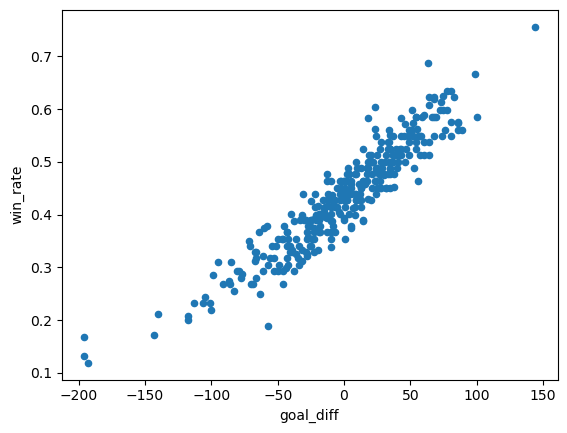

In [65]:
train_part.plot.scatter(x = 'goal_diff', y ='win_rate')

In [66]:
corr_goal_wins = train_part['goal_diff'].corr(train_part['win_rate'])
corr_goal_wins

np.float64(0.9356247173392863)

In [67]:
max_diff_index = train_part['goal_diff'].idxmax()
train_part.loc[max_diff_index, ['team', 'year', 'goal_diff', 'win_rate']]

team         Detroit Red Wings
year                      1995
goal_diff                  144
win_rate                 0.756
Name: 126, dtype: object

<Axes: xlabel='win_rate', ylabel='future_win_rate'>

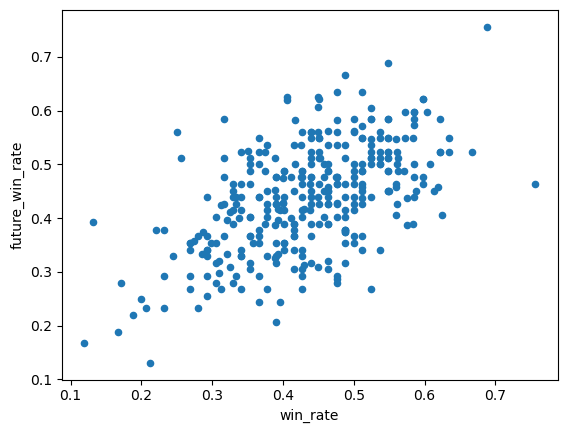

In [68]:
train_part.plot.scatter(x = 'win_rate', y = 'future_win_rate')

In [69]:
train_part['win_rate'].corr(train_part['future_win_rate'])

np.float64(0.5614986923361133)

In [70]:
win_rate_variance = train_part['future_win_rate'] - train_part['win_rate']
win_rate_variance.head()

0   -0.100
1    0.000
2   -0.187
3   -0.163
4    0.112
dtype: float64

In [71]:
win_rate_variance.abs().median()

0.061

In [72]:
max_var_index = win_rate_variance.abs().idxmax()
train_part.loc[max_var_index, ['team', 'year', 'target_year', 'win_rate', 'future_win_rate']]

team               Quebec Nordiques
year                           1991
target_year                    1992
win_rate                       0.25
future_win_rate                0.56
Name: 36, dtype: object

**Ответ 3.2:**

_Ваш ответ со ссылками на результаты собственной работы._
1-ая гипотеза подтвердилась, разница шайб сильно положительно связана с винрейтом в текущем сезоне, коэффициент корреляции Пирсона составил 0.936, что совпадает с диаграммой точек

Максимальная разница шайб в train — у Detroit Red Wings за 1995 год +144 при винрейте 75,6%. При этом связь показателей одного сезона ещё не доказывает, что разница шайб поможет предсказывать успешность в следующем.


2-ая гипотеза подтвердилась частично, связь между текущим и будущим винрейтом положительная, но слабее ожидаемой. Корреляция Пирсона составила 0.561, медиана абсолютного изменения — 0.061

При этом встречаются большие изменения, у Quebec Nordiques винрейт вырос с 0.25 в 1991 году до 0.56 в 1992 — на 31, текущий винрейт имеет смысл использовать как признак, но найденная связь ещё не гарантирует хорошего прогноза target.

## Раздел 4. Модели и эксперименты: 25 баллов

### 4.1. Постройте ориентиры

На train обучите простой константный baseline и оцените его на validation.
Отдельно используйте текущий `win_rate` как простую оценку для ранжирования
будущего класса. Посчитайте ROC-AUC обоих ориентиров и объясните,
какую планку задаёт каждый из них для обучаемой модели.

In [73]:
baseline = train_part['target'].mean()
baseline

np.float64(0.4911242603550296)

In [74]:
baseline_prediction = [baseline] * len(validation_part)
print(baseline_prediction[:5])
len(baseline_prediction)

[np.float64(0.4911242603550296), np.float64(0.4911242603550296), np.float64(0.4911242603550296), np.float64(0.4911242603550296), np.float64(0.4911242603550296)]


89

In [75]:
roc_auc_score(validation_part['target'], baseline_prediction)

0.5

In [76]:
roc_auc_score(validation_part['target'], validation_part['win_rate'])

0.756838905775076

**Ответ 4.1:**

_Ваш ответ со ссылками на результаты собственной работы._

Константный baseline выдаёт всем командам долю класса 1 из train — около 0.491, его ROC-AUC на validation равен 0.5, одинаковые оценки не позволяют различать команды.

Второй ориентир использует текущий win_rate для ранжирования будущей успешности. Его ROC-AUC составил 0.757, это более содержательная планка, тк обучаемую модель нужно сравнивать не только с константным прогнозом, но и с этим простым правилом.

### 4.2. Постройте первую модель

Обучите логистическую регрессию. Самостоятельно выберите признаки и обоснуйте выбор.
Обработку пропусков и масштабирование включите в Pipeline и обучайте только на train.
Посчитайте ROC-AUC на validation и сравните с обоими ориентирами.
Объясните результат без использования test.

In [77]:
x_train = train_part[['win_rate', 'goal_diff']].copy()
y_train = train_part['target']

In [78]:
x_validation = validation_part[['win_rate', 'goal_diff']].copy()
y_validation = validation_part['target']

In [79]:
scaler = StandardScaler()
imputer = SimpleImputer(strategy='median')
classifier = LogisticRegression(max_iter=1000)

In [80]:
model = Pipeline([
    ('imputer', imputer),
    ('scaler', scaler),
    ('classifier', classifier)
])

In [81]:
model.fit(x_train, y_train)

,steps,"[('imputer', ...), ('scaler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,copy,True


In [82]:
validation_proba = model.predict_proba(x_validation)
validation_proba[:5]

array([[0.38800376, 0.61199624],
       [0.74296698, 0.25703302],
       [0.13943285, 0.86056715],
       [0.26341965, 0.73658035],
       [0.15038518, 0.84961482]])

In [83]:
validation_scores = validation_proba[:, 1]
roc_auc_score(y_validation, validation_scores)

0.7720364741641338

**Ответ 4.2:**

_Ваш ответ со ссылками на результаты собственной работы._

Обучил логистическую регрессию на двух признаках, текущем винрейте и разнице шайб. Винрейт был связан с результатом следующего сезона, а разницу шайб добавил как ещё один показатель текущей игры команды.

В Pipeline включил заполнение пропусков медианой и стандартизацию:, те вычитание среднего и деление на стандартное отклонение. В выбранных признаках пропусков не было, обработка и модель обучались только на train.

ROC-AUC на validation составил 0.772, против 0.500 у константного baseline и 0.757 у текущего винрейта, улучшение получилось небольшим — около 0.015. Пока нельзя утверждать, что оно устойчиво или связано именно с добавлением разницы шайб

### 4.3. Проведите собственный эксперимент

Выберите одно осмысленное изменение: состав признаков, способ обработки данных,
параметры или другой алгоритм. До запуска запишите ожидаемый эффект и его причину.
Изменяйте одну понятную часть решения, сравните варианты на validation
и зафиксируйте выбор финальной модели до просмотра test.
Дополнительные эксперименты допустимы, но их количество само по себе не оценивается.

Попробуем првоерить логистическую регрессию без разницы голов, тк похожие признаки могут давать мало дополнительной информации, и более простая модель иногда лучше работает на новых данных

In [84]:
x_train_single = train_part[['win_rate']]
x_validation_single = validation_part[['win_rate']]

In [85]:
model_single = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=1000))
])


In [86]:
model_single.fit(x_train_single, y_train)

,steps,"[('imputer', ...), ('scaler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,copy,True


In [87]:
model_single.predict_proba(x_validation_single)[:5]

array([[0.33092747, 0.66907253],
       [0.73470435, 0.26529565],
       [0.09237081, 0.90762919],
       [0.1940796 , 0.8059204 ],
       [0.09237081, 0.90762919]])

In [88]:
single_scores = model_single.predict_proba(x_validation_single)[:, 1]

In [89]:
roc_auc_score(y_validation, single_scores)

0.756838905775076

**Ответ 4.3:**

_Ваш ответ со ссылками на результаты собственной работы._

Ожидал, что удаление разницы шайб улучшит качество, поскольку этот признак сильно коррелирует с винрейтом

Гипотеза не подтвердилась, метрика на validation снизился с 0.772 до 0.757, поэтому лучше выбрать модель с двумя признаками — win_rate и goal_diff. В Pipeline остаются заполнение пропусков медианой, StandardScaler и LogisticRegression с max_iter=1000, остальные параметры — по умолчанию

## Раздел 5. Итоговая оценка и анализ ошибок: 15 баллов

### 5.1. Проведите итоговую оценку

Зафиксируйте выбранную модель, признаки и параметры, затем один раз оцените её на test.
Покажите ROC-AUC, F1 и accuracy при пороге 0.5 для выбранной модели
и сопоставимых baseline. Объясните различия между метриками и сравните
результаты validation и test. После этого не меняйте выбранное решение.

In [90]:
x_test = test_part[['win_rate', 'goal_diff']]
y_test = test_part['target']

In [91]:
test_scores = model.predict_proba(x_test)[:, 1]

In [92]:
test_scores[:5]

array([0.63490229, 0.40340602, 0.90924608, 0.63789575, 0.71005105])

In [93]:
test_auc = roc_auc_score(y_test, test_scores)
test_auc

0.7596251266464031

In [94]:
test_predictions = (test_scores >= 0.5).astype(int)

In [95]:
test_predictions_accur = accuracy_score(y_test, test_predictions)
test_predictions_accur

0.6629213483146067

In [96]:
f1_test = f1_score(y_test, test_predictions)
f1_test

0.7058823529411765

In [102]:
constant_test_scores = np.full(len(test_part), baseline)
constant_test_pred = (constant_test_scores >= 0.5).astype(int)

constant_test_auc = roc_auc_score(y_test, constant_test_scores)
constant_test_accuracy = accuracy_score(y_test, constant_test_pred)
constant_test_f1 = f1_score(
    y_test, constant_test_pred, zero_division=0
)

print(constant_test_auc)
print(constant_test_accuracy)
print(constant_test_f1)


0.5
0.5280898876404494
0.0


In [98]:
wr_test_scores = test_part['win_rate']
wr_test_predictions = (wr_test_scores >= 0.5).astype(int)

wr_test_auc = roc_auc_score(y_test, wr_test_scores)
wr_test_accuracy = accuracy_score(y_test, wr_test_predictions)
wr_test_f1 = f1_score(
    y_test, wr_test_predictions, zero_division=0
)

print(wr_test_auc)
print(wr_test_accuracy)
print(wr_test_f1)

0.7403748733535969
0.6404494382022472
0.6521739130434783


**Ответ 5.1:**

_Ваш ответ со ссылками на результаты собственной работы._

До просмотра test выбрал логистическую регрессию с признаками win_rate и goal_diff. Обработка осталась пржней, у LogisticRegression установлен max_iter=1000, остальные параметры оставлены по умолчанию, обучил все только на тренировчных данных
На test получил ROC-AUC 0.760, F1 0.706 и accuracy 0.663, модель правильно классифицировала 59 из 89 примеров. ROC-AUC немного снизился относительно validation, с 0.772 до 0.760

ROC-AUC оценивает ранжирование по числовым прогнозам, accuracy показывает долю правильных классов, а F1 учитывает ложные положительные ответы и пропущенные положительные случаи. Для F1 и accuracy использован порог 0.5, у ориентира по текущему винрейту это порог самой доли побед, которая не является обученной вероятностью будущего успеха.

Константный baseline использует долю класса 1 из train, равную примерно 0.491, при пороге 0.5 он всегда предсказывает 0, поэтому его F1 равен 0, а ROC-AUC — 0.5

### 5.2. Разберите ошибки

Выберите от трёх до пяти ошибок финальной модели по явно указанному принципу.
Это могут быть наиболее уверенные ошибки, отдельный тип ошибки или другой
обоснованный набор. Покажите идентификаторы строк, вероятности и значения,
необходимые для анализа. Найдите общие черты и различия; отделите факты
из таблицы от гипотез и назовите данные, нужные для проверки одной гипотезы.

In [99]:
test_analysis = test_part.copy()

test_analysis['probability'] = test_scores
test_analysis['prediction'] = test_predictions

errors = test_analysis[
    test_analysis['prediction'] != test_analysis['target']
].copy()

print('Количество ошибок:', len(errors))

Количество ошибок: 30


In [100]:
errors['confidence'] = np.where(
    errors['prediction'] == 1,
    errors['probability'],
    1 - errors['probability']
)

top_errors = errors.sort_values(
    'confidence', ascending=False
).head(5)

top_errors[[
    'team', 'year', 'target_year',
    'win_rate', 'goal_diff',
    'probability', 'prediction', 'target',
    'future_win_rate', 'future_median'
]]

,team,year,target_year,win_rate,goal_diff,probability,prediction,target,future_win_rate,future_median
464,Boston Bruins,2008,2009,0.646,78,0.909246,1,0,0.476,0.488
514,Phoenix Coyotes,2009,2010,0.610,23,0.807976,1,0,0.524,0.524
509,New Jersey Devils,2009,2010,0.585,31,0.793318,1,0,0.463,0.524
535,Los Angeles Kings,2010,2011,0.561,21,0.742964,1,0,0.488,0.500
495,Buffalo Sabres,2009,2010,0.549,28,0.741209,1,0,0.524,0.524


**Ответ 5.2:**

_Ваш ответ со ссылками на результаты собственной работы._

Выбрал пять наиболее уверенных ошибок, отсортировал ошибочные прогнозы по вероятности предсказанного класса, все пять случаев оказались ложными положительными — модель ожидала успешность, но фактический target равен 0

Самая уверенная ошибка — Boston Bruins, вероятность успеха 0.909, после винрейта 0.646 и разницы шайб +78 в 2008 году команда получила винрейт 0.476 в 2009, ниже медианы 0.488. У New Jersey Devils, винрейт снизился с 0.585 до 0.463 при будущей медиане 0.524, вероятность модели была 0.793.

Общее у этих случаев — положительная текущая разница шайб, текущий винрейт выше 0.5 и его снижение в следующем сезоне, при этом четыре команды оказались на будущей медиане или всего на 0.012 ниже неё, у New Jersey Devils отставание составило 0.061, получается, уверенная ошибка классификации не всегда означает большой отрыв от границы успешности.

Возможное объяснение снижения результатов — изменения состава или травмы игроков, но это гипотеза, а не вывод из таблицы.

## Раздел 6. Выводы и воспроизводимость: 5 баллов

### 6.1. Сформулируйте выводы

Сформулируйте основные выводы и ограничения работы со ссылками на свои графики,
строки и метрики. Опишите минимум два решения, которые вы изменили
или подтвердили после получения результатов. Назовите одно улучшение,
которое вы сознательно не стали выполнять, и объясните причину.
Убедитесь, что последовательность работы и финальные параметры можно воспроизвести.

In [101]:
print('Python:', sys.version)
print('pandas:', pd.__version__)
print('NumPy:', np.__version__)
print('scikit-learn:', sklearn.__version__)
print('requests:', requests.__version__)
print('beautifulsoup4:', bs4.__version__)

print('\nПризнаки:', list(x_train.columns))
print('\nPipeline:')
print(model)

print('\nПараметры логистической регрессии:')
print(model.named_steps['classifier'].get_params())

print('\nРазмеры выборок:')
print({
    'train': len(train_part),
    'validation': len(validation_part),
    'test': len(test_part)
})

Python: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:11:29) [Clang 20.1.8 ]
pandas: 2.3.3
NumPy: 2.3.5
scikit-learn: 1.7.2
requests: 2.32.5
beautifulsoup4: 4.13.5

Признаки: ['win_rate', 'goal_diff']

Pipeline:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('classifier', LogisticRegression(max_iter=1000))])

Параметры логистической регрессии:
{'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 1000, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': None, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}

Размеры выборок:
{'train': 338, 'validation': 89, 'test': 89}


**Ответ 6.1:**

_Ваш ответ со ссылками на результаты собственной работы._


Собрал 582 записи с 24 страниц сайта, после соединения соседних сезонов одной команды получил 516 примеров, временное разделение позволило проверить прогноз более поздних сезонов по данным прошлого.

На train разница шайб сильно связана с винрейтом того же сезона, корреляция 0.936, связь винрейтов соседних сезонов слабее — 0.561, медианное абсолютное изменение составляет 0.061, поэтому текущие результаты полезны для прогноза, но не определяют будущий успех однозначно.

После проверки данных сохранил 224 пропуска в ot_losses как неизвестные значения, оснований считать их нулями не было. После эксперимента сохранил оба признака модели — win_rate и goal_diff, удаление разницы шайб снизило ROC-AUC на validation с 0.772 до 0.757.

На test выбранная модель получила ROC-AUC 0.760, F1 0.706 и accuracy 0.663, конкретные ошибки и их возможные объяснения рассмотрены в разделе 5.2, ограничения работы — небольшая проверочная выборка, повторные наблюдения одних команд и отсутствие информации о составе, травмах и других изменениях между сезонами.

Сознательно не стал добавлять сведения о составах команд: это потребовало бы отдельного источника и проверки доступности информации на момент прогноза. После просмотра test решение не менял. Исходная выгрузка сохранена в CSV, код подготовки, параметры и версии библиотек указаны в ноутбуке.